<a href="https://colab.research.google.com/github/NielsRogge/Transformers-Tutorials/blob/master/YOLOS/Fine_tuning_YOLOS_for_object_detection_on_custom_dataset_(balloon).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Fine-tuning YOLOS on a custom dataset for object detection

In this notebook, we are going to fine-tune YOLOS on a custom object detection dataset. The goal for the model is to recognize the structure of restaurant menus (titles, subtitles, menu items, descriptions, variants and prices) in synthetic menu renders produced by `genmenu`.

* Original YOLOS paper: https://arxiv.org/abs/2106.00666
* Original DETR repo: https://github.com/hustvl/YOLOS

Important note regarding **GPU memory**: `YolosImageProcessor` by default resizes each image to have a `min_size` of 800 pixels and a `max_size` of 1333 pixels (as these are the default values that DETR and YOLOS use at *inference* time). Note that this can stress-test the memory of your GPU when *training* the model (the bigger the images, the more patches are used which are sent through the Transformer encoder). It's advised to use a batch size of 2 on a single GPU. You can of course also initialize `YolosImageProcessor` with a smaller `size` and/or `max_size` to use bigger batches. 

Note regarding **augmentation**: DETR/YOLOS actually use several image augmentations during training. One of them is **scale augmentation**: they set the `min_size` randomly to be one of [480, 512, 544, 576, 608, 640, 672, 704, 736, 768, 800] as can be seen [here](https://github.com/facebookresearch/detr/blob/a54b77800eb8e64e3ad0d8237789fcbf2f8350c5/datasets/coco.py#L122). However, we are not going to add any of the augmentations that are used in the original implementation during training. It works fine without them.

Also big thanks to the creator of [this notebook](https://github.com/woctezuma/finetune-detr/blob/master/finetune_detr.ipynb), which helped me a lot in understanding how to fine-tune DETR on a custom dataset.


## Set up environment

In [1]:
!uv pip install -q transformers torch torchvision pytorch-lightning timm datasets pycocotools scipy


## Load dataset

Generate the dataset first by running `uv run genmenu` from the repository root (see `uv run genmenu --help` for options). It writes a Hugging Face object-detection `imagefolder` dataset (images + `metadata.jsonl` per split) to `out/dataset`, along with `labels.json` containing the label map.


In [2]:
from datasets import load_dataset

DATASET_DIR = "out/dataset"

menus = load_dataset("imagefolder", data_dir=DATASET_DIR)
menus

Resolving data files:   0%|          | 0/8001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2001 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'image_id', 'width', 'height', 'objects', 'layout', 'price_format', 'mode', 'scheme', 'heading_font', 'body_font'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['image', 'image_id', 'width', 'height', 'objects', 'layout', 'price_format', 'mode', 'scheme', 'heading_font', 'body_font'],
        num_rows: 2000
    })
})

The Hub dataset already stores the annotations in a Datasets-compatible object-detection format. To keep the rest of the notebook unchanged, we reconstruct a lightweight COCO API from the dataset entries before passing them to `YolosImageProcessor`.

In [3]:
print(menus["train"].column_names)
print(menus["train"][0]["objects"].keys())

['image', 'image_id', 'width', 'height', 'objects', 'layout', 'price_format', 'mode', 'scheme', 'heading_font', 'body_font']
dict_keys(['id', 'bbox', 'categories', 'area'])


In [4]:
import json

with open(f"{DATASET_DIR}/labels.json") as f:
    id2label = {int(k): v for k, v in json.load(f)["id2label"].items()}
label2id = {label: idx for idx, label in id2label.items()}
id2label

{0: 'title',
 1: 'subtitle',
 2: 'menu_item',
 3: 'item_title',
 4: 'item_description',
 5: 'variant',
 6: 'variant_title',
 7: 'variant_price',
 8: 'item_price',
 9: 'section_title'}

## Create PyTorch dataset + dataloaders

We now wrap the Hub dataset in a small PyTorch dataset that recreates the COCO-style annotations expected by `YolosImageProcessor` and by the COCO evaluation code later in the notebook.

In [6]:
import os
from pycocotools.coco import COCO
from torch.utils.data import Dataset

class HuggingFaceCocoDetection(Dataset):
    def __init__(self, dataset, image_processor):
        self.dataset = dataset
        self.image_processor = image_processor
        self.ids = list(dataset["image_id"])
        self.id2index = {image_id: idx for idx, image_id in enumerate(self.ids)}
        self.coco = COCO()
        self.coco.dataset = self._build_coco_dataset()
        self.coco.createIndex()

    def _build_coco_dataset(self):
        images = []
        annotations = []

        for example in self.dataset:
            image = example["image"]
            image_id = example["image_id"]
            images.append(
                {
                    "id": image_id,
                    "file_name": os.path.basename(image.filename),
                    "width": example["width"],
                    "height": example["height"],
                }
            )

            for annotation_id, bbox, category_id, area in zip(
                example["objects"]["id"],
                example["objects"]["bbox"],
                example["objects"]["categories"],
                example["objects"]["area"],
            ):
                annotations.append(
                    {
                        "id": annotation_id,
                        "image_id": image_id,
                        "category_id": category_id,
                        "bbox": bbox,
                        "area": area,
                        "iscrowd": 0,
                    }
                )

        return {
            "images": images,
            "annotations": annotations,
            "categories": [{"id": idx, "name": name, "supercategory": "menu"} for idx, name in id2label.items()],
        }

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = example["image"].convert("RGB")
        image_id = example["image_id"]
        target = {"image_id": image_id, "annotations": self.coco.imgToAnns[image_id]}
        encoding = self.image_processor(images=image, annotations=target, return_tensors="pt")
        pixel_values = encoding["pixel_values"].squeeze()
        target = encoding["labels"][0]

        return pixel_values, target

    def get_image(self, image_id):
        return self.dataset[self.id2index[image_id]]["image"].convert("RGB")

Based on the class defined above, we create training and validation datasets from the Hub splits.

In [7]:
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    "hustvl/yolos-base",
    size={"shortest_edge": 512, "longest_edge": 864},
)

train_dataset = HuggingFaceCocoDetection(dataset=menus["train"], image_processor=image_processor)
val_dataset = HuggingFaceCocoDetection(dataset=menus["validation"], image_processor=image_processor)

creating index...
index created!
creating index...
index created!


As you can see, this dataset is tiny:

In [8]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(val_dataset))

Number of training examples: 8000
Number of validation examples: 2000


Let's verify an example by visualizing it. We can still access the reconstructed COCO API through `train_dataset.coco`.

Image n°8001


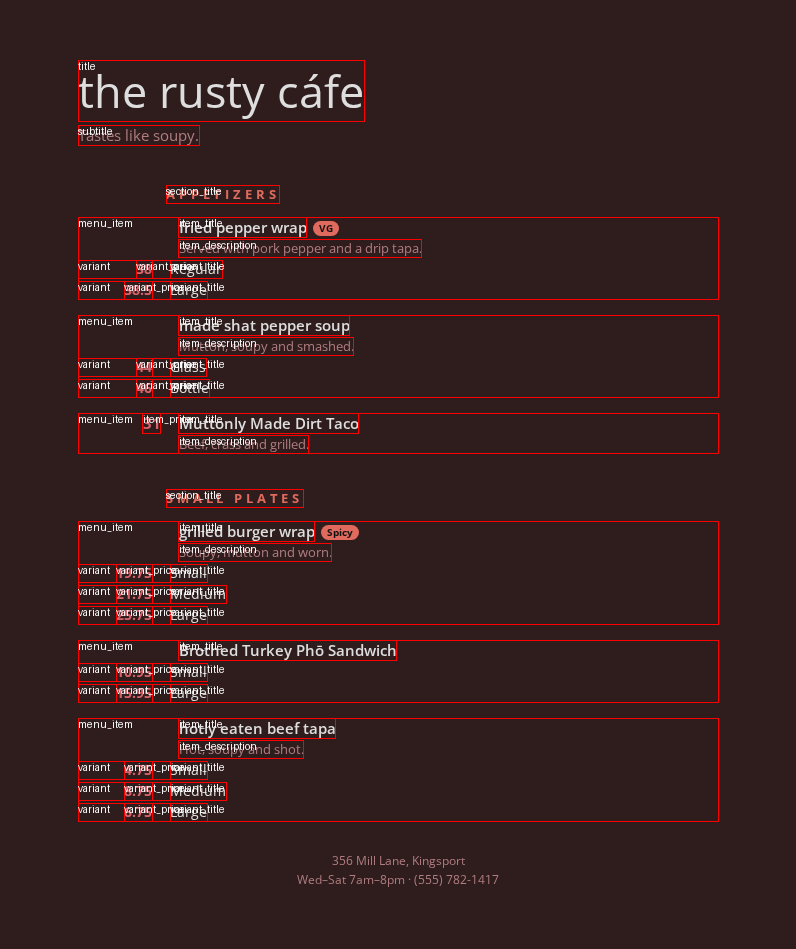

In [9]:
import numpy as np
from PIL import ImageDraw

# based on https://github.com/woctezuma/finetune-detr/blob/master/finetune_detr.ipynb
image_ids = val_dataset.coco.getImgIds()
# let's pick a random image
# image_id = image_ids[np.random.randint(0, len(image_ids))]
image_id = image_ids[1]
print('Image n°{}'.format(image_id))
image = val_dataset.get_image(image_id)

annotations = val_dataset.coco.imgToAnns[image_id]
draw = ImageDraw.Draw(image, "RGBA")

cats = val_dataset.coco.cats
id2label = {k: v['name'] for k,v in cats.items()}

for annotation in annotations:
  box = annotation['bbox']
  class_idx = annotation['category_id']
  x,y,w,h = tuple(box)
  draw.rectangle((x,y,x+w,y+h), outline='red', width=1)
  draw.text((x, y), id2label[class_idx], fill='white')

image

Next, let's create corresponding dataloaders. We define a custom `collate_fn` to batch images together. As DETR resizes images to have a min size of 800 and a max size of 1333, images can have different sizes. We pad images (`pixel_values`) to the largest image in a batch.  

In [10]:
import torch
from torch.utils.data import DataLoader

def collate_fn(batch):
  # zero-pad every image (C, H, W) at the bottom/right to the largest size in the batch
  pixel_values = [item[0] for item in batch]
  max_h = max(pv.shape[1] for pv in pixel_values)
  max_w = max(pv.shape[2] for pv in pixel_values)
  padded = torch.zeros((len(pixel_values), pixel_values[0].shape[0], max_h, max_w), dtype=pixel_values[0].dtype)
  for i, pv in enumerate(pixel_values):
    padded[i, :, :pv.shape[1], :pv.shape[2]] = pv
  labels = [item[1] for item in batch]
  batch = {}
  batch['pixel_values'] = padded
  batch['labels'] = labels
  return batch

train_dataloader = DataLoader(train_dataset, collate_fn=collate_fn, batch_size=1, shuffle=True)
val_dataloader = DataLoader(val_dataset, collate_fn=collate_fn, batch_size=1)
batch = next(iter(train_dataloader))

Let's verify the keys of a single batch:

In [11]:
batch.keys()

dict_keys(['pixel_values', 'labels'])

Let's verify the shape of the `pixel_values`, and check the `target`::

In [12]:
pixel_values, target = train_dataset[0]

In [13]:
pixel_values.shape

torch.Size([3, 512, 512])

In [14]:
print(target)

{'size': tensor([512, 512]), 'image_id': tensor([0]), 'class_labels': tensor([0, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 9, 9]), 'boxes': tensor([[0.5000, 0.0709, 0.3359, 0.0415],
        [0.5000, 0.1091, 0.0643, 0.0232],
        [0.5000, 0.2372, 0.8374, 0.0613],
        [0.5000, 0.2983, 0.8374, 0.0608],
        [0.5000, 0.3591, 0.8374, 0.0608],
        [0.5000, 0.4199, 0.8374, 0.0608],
        [0.5000, 0.4807, 0.8374, 0.0608],
        [0.5000, 0.6088, 0.8374, 0.0613],
        [0.5000, 0.6699, 0.8374, 0.0608],
        [0.5000, 0.7307, 0.8374, 0.0608],
        [0.5000, 0.7915, 0.8374, 0.0608],
        [0.5000, 0.8523, 0.8374, 0.0608],
        [0.5000, 0.9131, 0.8374, 0.0608],
        [0.1704, 0.2268, 0.1665, 0.0232],
        [0.1685, 0.2876, 0.1626, 0.0232],
        [0.1568, 0.3485, 0.1392, 0.0232],
        [0.13

## Train the model using PyTorch Lightning

Here we define a `LightningModule`, which is an `nn.Module` with some extra functionality.

For more information regarding PyTorch Lightning, I recommend the [docs](https://pytorch-lightning.readthedocs.io/en/latest/?_ga=2.35105442.2002381006.1623231889-1738348008.1615553774) as well as the [tutorial notebooks](https://github.com/PyTorchLightning/lightning-tutorials/tree/aeae8085b48339e9bd9ab61d81cc0dc8b0d48f9c/.notebooks/starters). 

You can of course just train the model in native PyTorch as an alternative.

In [15]:
import pytorch_lightning as pl
from transformers import AutoModelForObjectDetection
import torch

class Detr(pl.LightningModule):

     def __init__(self, lr, weight_decay):
         super().__init__()
         # replace COCO classification head with custom head
         self.model = AutoModelForObjectDetection.from_pretrained("hustvl/yolos-small", 
                                                             num_labels=len(id2label),
                                                             id2label=id2label,
                                                             label2id=label2id,
                                                             ignore_mismatched_sizes=True)
         # see https://github.com/PyTorchLightning/pytorch-lightning/pull/1896
         self.lr = lr
         self.weight_decay = weight_decay

     def forward(self, pixel_values):
       outputs = self.model(pixel_values=pixel_values)

       return outputs
     
     def common_step(self, batch, batch_idx):
       pixel_values = batch["pixel_values"]
       labels = [{k: v.to(self.device) for k, v in t.items()} for t in batch["labels"]]

       outputs = self.model(pixel_values=pixel_values, labels=labels)

       loss = outputs.loss
       loss_dict = outputs.loss_dict

       return loss, loss_dict

     def training_step(self, batch, batch_idx):
        loss, loss_dict = self.common_step(batch, batch_idx)     
        # logs metrics for each training_step,
        # and the average across the epoch
        self.log("training_loss", loss)
        for k,v in loss_dict.items():
          self.log("train_" + k, v.item())

        return loss

     def validation_step(self, batch, batch_idx):
        loss, loss_dict = self.common_step(batch, batch_idx)     
        self.log("validation_loss", loss)
        for k,v in loss_dict.items():
          self.log("validation_" + k, v.item())

        return loss

     def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.lr,
                                  weight_decay=self.weight_decay)
        
        return optimizer

     def train_dataloader(self):
        return train_dataloader

     def val_dataloader(self):
        return val_dataloader

As PyTorch Lightning by default logs to Tensorboard, let's start it:

Here we define the model, and verify the outputs.

In [16]:
model = Detr(lr=2.5e-5, weight_decay=1e-4)

outputs = model(pixel_values=batch['pixel_values'])

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `91`.


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] YolosForObjectDetection LOAD REPORT from: hustvl/yolos-small
Key                                     | Status   |                                                                                         
----------------------------------------+----------+-----------------------------------------------------------------------------------------
class_labels_classifier.layers.2.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([92]) vs model:torch.Size([11])          
class_labels_classifier.layers.2.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([92, 384]) vs model:torch.Size([11, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


The logits are of shape `(batch_size, num_queries, number of classes + 1)`. We model internally adds an additional "no object class", which explains why we have one additional output for the class dimension. 

In [17]:
outputs.logits.shape

torch.Size([1, 100, 11])

Next, let's train! We train for a maximum of 300 training steps, and also use gradient clipping. You can refresh Tensorboard above to check the various losses.

In [18]:
from pytorch_lightning import Trainer

trainer = Trainer(accelerator="auto", max_steps=2000, gradient_clip_val=0.1, accumulate_grad_batches=4)
trainer.fit(model)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoi

┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type                    ┃ Params ┃ Mode ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━━┩
│ 0 │ model │ YolosForObjectDetection │ 30.7 M │ eval │     0 │
└───┴───────┴─────────────────────────┴────────┴──────┴───────┘

Trainable params: 30.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 30.7 M                                                                                               
Total estimated model params size (MB): 122.614                                                                    
Modules in train mode: 0                                                                                           
Modules in eval mode: 225                                                                                          
Total FLOPs: 0

Output()

/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/trainer/connectors/data_co
nnector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the 
value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.

/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/utilities/data.py:79: 
Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 1. To avoid any 
miscalculations, use `self.log(..., batch_size=batch_size)`.

/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/trainer/connectors/data_co
nnector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.

/home/lyra/.cache/uv/builds-v0/.tmp35RRUP/lib/python3.14/site-packages/pytorch_lightning/loops/fit_loop.py:538: 
Found 225 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If
this is intentional, you can ignore this warning.

`Trainer.fit` stopped: `max_steps=2000` reached.


In [19]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

In [20]:
import json
from pycocotools.cocoeval import COCOeval
from pycocotools.coco import COCO
from tqdm.notebook import tqdm
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.eval()

print("Running evaluation...")

all_results = []

for idx, batch in enumerate(tqdm(val_dataloader)):
    pixel_values = batch["pixel_values"].to(device)
    labels = [{k: v.to(device) for k, v in t.items()} for t in batch["labels"]]

    with torch.no_grad():
        outputs = model.model(pixel_values=pixel_values)

    orig_target_sizes = torch.stack([target["orig_size"] for target in labels], dim=0)
    results = image_processor.post_process_object_detection(outputs, target_sizes=orig_target_sizes, threshold=0.0)
    
    for target, result in zip(labels, results):
        image_id = target['image_id'].item()
        boxes = result['boxes'].cpu().numpy()
        scores = result['scores'].cpu().numpy()
        labels_pred = result['labels'].cpu().numpy()
        
        # Convert from xyxy to xywh format for COCO
        boxes_xywh = boxes.copy()
        boxes_xywh[:, 2] = boxes[:, 2] - boxes[:, 0]
        boxes_xywh[:, 3] = boxes[:, 3] - boxes[:, 1]
        
        for box, score, label in zip(boxes_xywh, scores, labels_pred):
            all_results.append({
                'image_id': image_id,
                'category_id': label.item(),
                'bbox': box.tolist(),
                'score': score.item(),
            })

# Run COCO evaluation
coco_gt = val_dataset.coco
coco_dt = coco_gt.loadRes(all_results)
coco_eval = COCOeval(coco_gt, coco_dt, 'bbox')
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

Running evaluation...


  0%|          | 0/2000 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.15s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=27.25s).
Accumulating evaluation results...
DONE (t=1.45s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.120
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.308
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.078
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.062
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.114
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.140
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.111
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.204
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.220
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

## Inference (+ visualization)

Let's visualize the predictions of DETR on the first image of the validation set.

In [21]:
!uv pip install matplotlib

Resolved 11 packages in 5.20s                                        
Installed 6 packages in 11ms                                
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.68.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + pyparsing==3.3.3


In [68]:
#We can use the image_id in target to know which image it is
pixel_values, target = val_dataset[10]

In [69]:
pixel_values = pixel_values.unsqueeze(0).to(device)
print(pixel_values.shape)

torch.Size([1, 3, 512, 512])


In [70]:
# forward pass to get class logits and bounding boxes
outputs = model(pixel_values=pixel_values)

In [74]:
import torch
import matplotlib.pyplot as plt

# colors for visualization
COLORS = [[0.000, 0.447, 0.741], [0.850, 0.325, 0.098], [0.929, 0.694, 0.125],
          [0.494, 0.184, 0.556], [0.466, 0.674, 0.188], [0.301, 0.745, 0.933]]

# for output bounding box post-processing
def box_cxcywh_to_xyxy(x):
    x_c, y_c, w, h = x.unbind(1)
    b = [(x_c - 0.5 * w), (y_c - 0.5 * h),
         (x_c + 0.5 * w), (y_c + 0.5 * h)]
    return torch.stack(b, dim=1)

def rescale_bboxes(out_bbox, size):
    img_w, img_h = size
    b = box_cxcywh_to_xyxy(out_bbox)
    b = b * torch.tensor([img_w, img_h, img_w, img_h], dtype=torch.float32)
    return b

def plot_results(pil_img, scores, labels, boxes):
    plt.figure(figsize=(16,10))
    plt.imshow(pil_img)
    ax = plt.gca()
    colors = COLORS * 100
    for score, label, (xmin, ymin, xmax, ymax), c in zip(scores.tolist(), labels.tolist(), boxes.tolist(), colors):
        ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                   fill=False, color=c, linewidth=3))
        text = f'{id2label[label]}: {score:0.2f}'
        ax.text(xmin, ymin, text, fontsize=8,
                bbox=dict(facecolor='yellow', alpha=0.5))
    plt.axis('off')
    plt.show()

In [75]:
def visualize_predictions(image, outputs, threshold=0.9):
  # post-process outputs
  target_sizes = torch.tensor(image.size[::-1]).unsqueeze(0).to(outputs.logits.device)
  results = image_processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=threshold)[0]

  # plot results
  plot_results(image, results['scores'].cpu(), results['labels'].cpu(), results['boxes'].cpu())

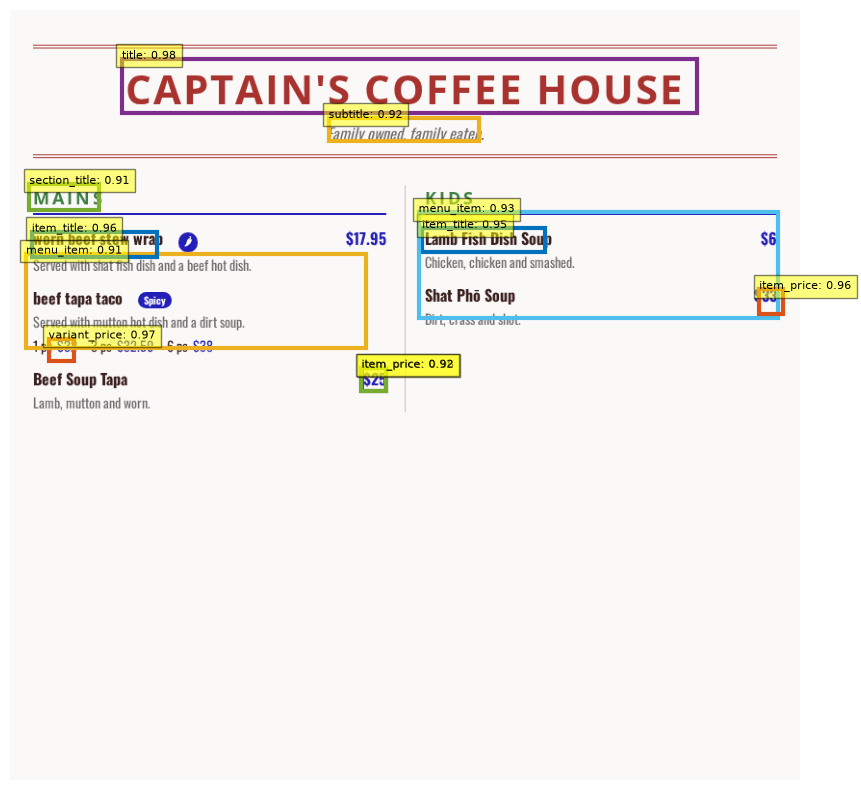

In [76]:
image_id = target['image_id'].item()
image = val_dataset.get_image(image_id)

visualize_predictions(image, outputs)